**Imorting Libraries**

In [424]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import color_sequences
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.api import ExponentialSmoothing, SimpleExpSmoothing, Holt
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller , kpss
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
import warnings
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
import statsmodels.api as sm
from statsmodels.tsa.stattools import kpss
from sklearn.linear_model import LinearRegression
print("Libraries Imported Successfully")

Libraries Imported Successfully


**Loading excel files**

In [425]:
df = pd.read_excel("/kaggle/input/data-msft/HistoricalData_MSFT.xlsx")
df.head()

,Date,Close
0,2025-12-31,483.62
1,2025-12-30,487.48
2,2025-12-29,487.10
3,2025-12-26,487.71
4,2025-12-24,488.02


**Converting the 'Date' column to datetime series. Sorting values in ascending order and setting 'Date' as the index for time-series operations**

In [426]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').set_index('Date')

df.head()

,Close
Date,
2021-01-08,219.62
2021-01-11,217.49
2021-01-12,214.93
2021-01-13,216.34
2021-01-14,213.02


In [427]:
df.head(10)

,Close
Date,
2021-01-08,219.62
2021-01-11,217.49
2021-01-12,214.93
2021-01-13,216.34
2021-01-14,213.02
2021-01-15,212.65
2021-01-19,216.44
2021-01-20,224.34
2021-01-21,224.97


In [428]:
df.describe()

,Close
count,1251.000000
mean,349.067162
std,86.926794
min,212.650000
25%,272.355000
50%,331.620000
75%,418.375000
max,542.070000


**Ploting the 'Close' price from the DataFrame against its index (Date)**

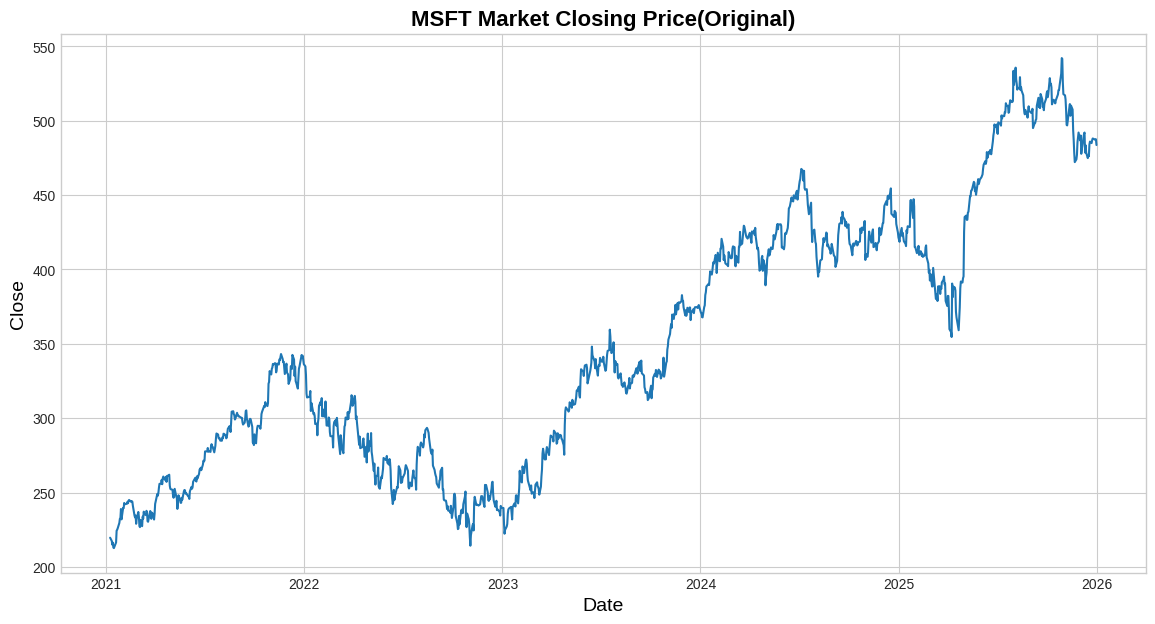

In [429]:
plt.style.available
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(14,7), dpi=100)
plt.xlabel ('Date', color = 'black', fontdict= {'fontweight': 'normal', 'fontstyle' :'normal', 'fontsize' : 14})
plt.ylabel ('Close', color = 'black', fontdict= {'fontweight': 'normal', 'fontstyle' :'normal', 'fontsize' : 14})
plt.title ('MSFT Market Closing Price(Original)', color = 'black', fontdict= {'fontweight': 'bold', 'fontstyle' :'normal', 'fontsize' : 16})

plt.plot (df['Close'])
plt.show ()

**Resampling the DataFrame to mean for each month and ploting the monthly resampled 'Close' prices**

In [430]:
df_m = df.resample('ME').mean()
df_m.head()

,Close
Date,
2021-01-31,223.426667
2021-02-28,240.066842
2021-03-31,233.674348
2021-04-30,255.580000
2021-05-31,247.395500


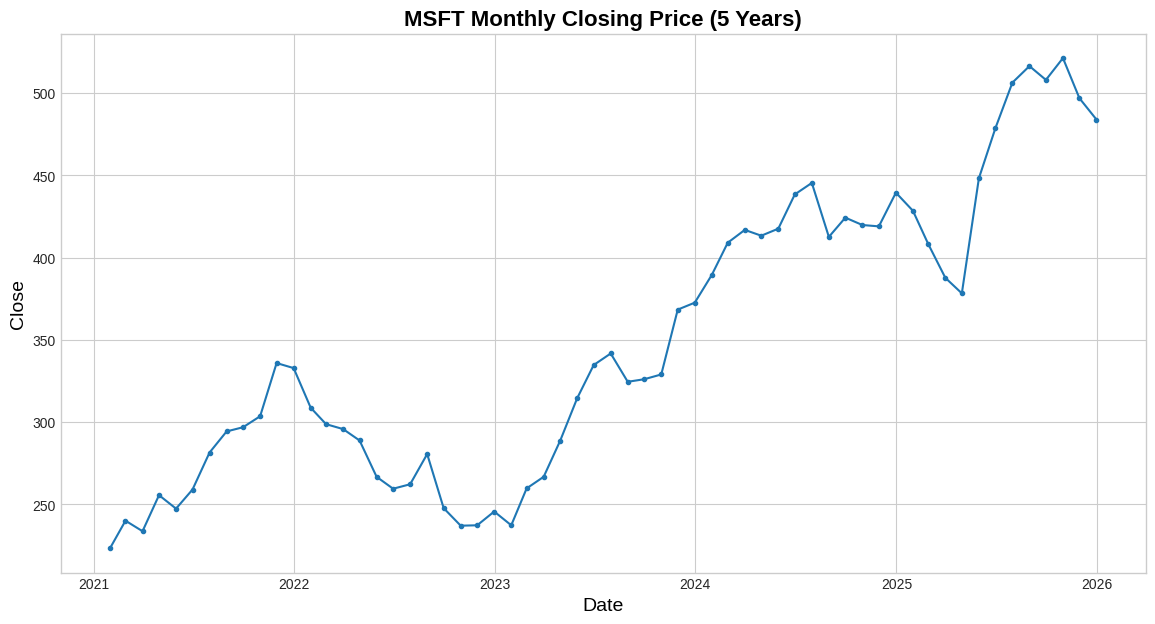

In [431]:
plt.style.available
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(14,7), dpi=100)
plt.xlabel ('Date', color = 'black', fontdict= {'fontweight': 'normal', 'fontstyle' :'normal', 'fontsize' : 14})
plt.ylabel ('Close', color = 'black', fontdict= {'fontweight': 'normal', 'fontstyle' :'normal', 'fontsize' : 14})
plt.title ('MSFT Monthly Closing Price (5 Years)', color = 'black', fontdict= {'fontweight': 'bold', 'fontstyle' :'normal', 'fontsize' : 16})
plt.plot (df_m, marker="o", markersize=3)
plt.show ()

In [432]:
df_m.describe()

,Close
count,60.000000
mean,348.374760
std,87.265151
min,223.426667
25%,266.739218
50%,330.874886
75%,417.887170
max,521.203043


**Rolling stats on monthly data**

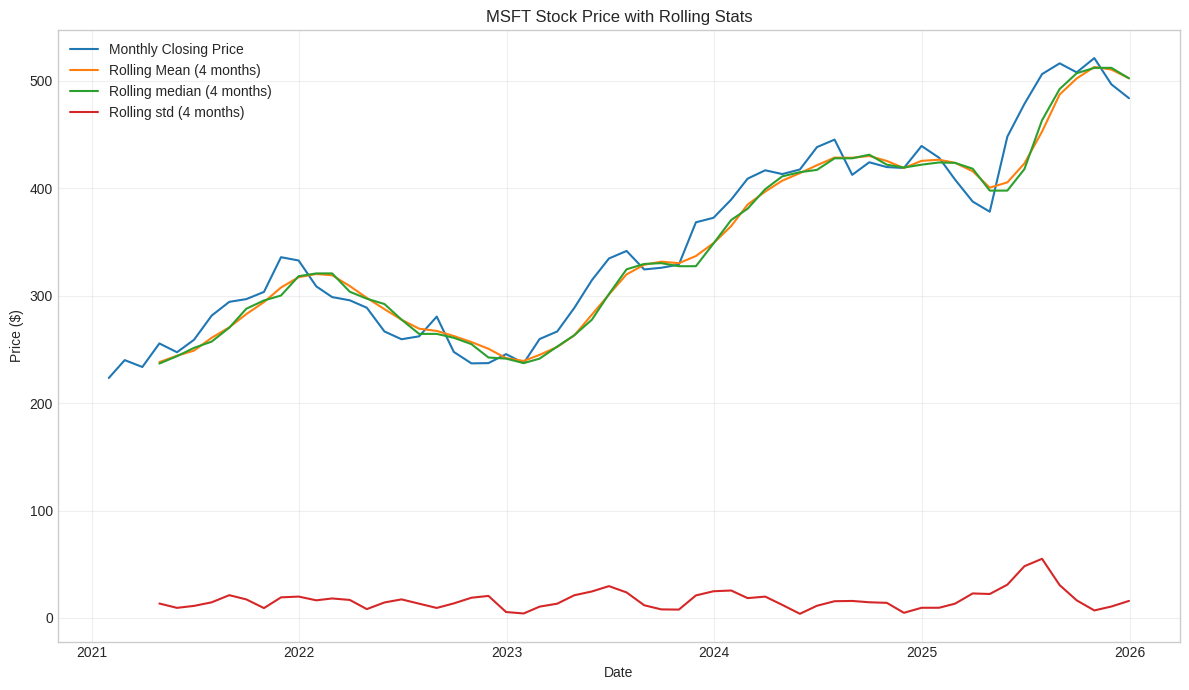

In [433]:
roll_mean=df_m['Close'].rolling(4).mean()
roll_median=df_m['Close'].rolling(4).median()
roll_std=df_m['Close'].rolling(4).std()

plt.figure(figsize=(12, 7))
plt.plot(df_m, label='Monthly Closing Price')
plt.plot(roll_mean, label='Rolling Mean (4 months)')
plt.plot(roll_median, label='Rolling median (4 months)')
plt.plot(roll_std, label='Rolling std (4 months)')

plt.title('MSFT Stock Price with Rolling Stats')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Decompose the time series (trend/seasonal/residual)**

**Additive decomposition**

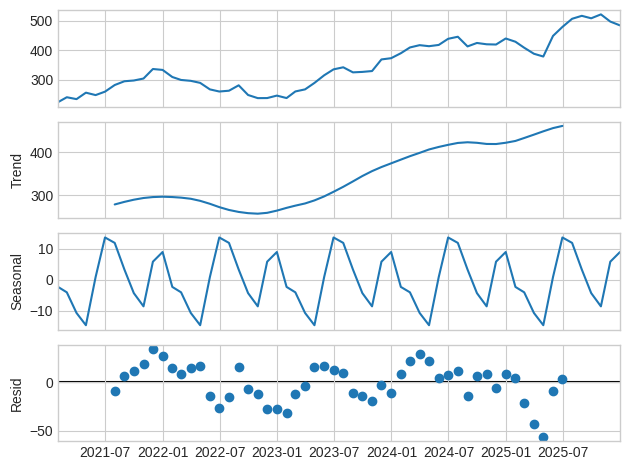

In [434]:
add = seasonal_decompose(df_m, model="additive")
add.plot()
plt.show()

**Multiplicative decomposition**

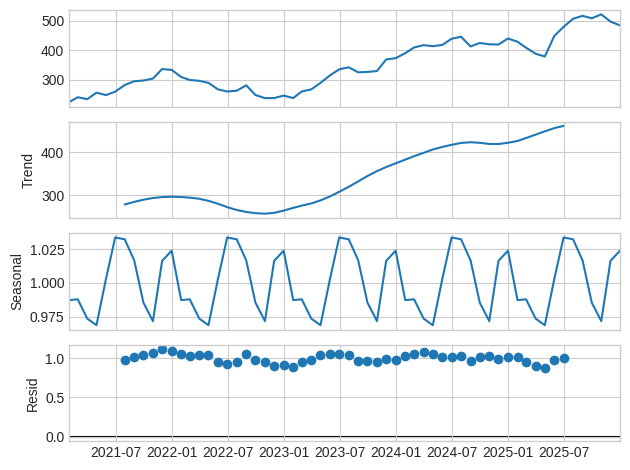

In [435]:
mul = seasonal_decompose(df_m, model="multiplicative")
mul.plot()
plt.show()

**Additive residual vs multiplicative residual**

In [436]:
add_resid_std = add.resid.dropna().std()
mul_resid_std = mul.resid.dropna().std()

print("Additive residual std:", add_resid_std)
print("Multiplicative residual std:", mul_resid_std)

Additive residual std: 19.057527878128855
Multiplicative residual std: 0.05603506943903308


**Forecast with required methods (12 months)**

**Split the Data into Training and Testing Sets**

In [437]:
train_size = int(len(df_m) * 0.8)
train = df_m.iloc[:train_size]
test = df_m.iloc[train_size:]

print("Training period:", len(train), "months")
print("Testing period:", len(test), "months")

Training period: 48 months
Testing period: 12 months


**Create metric functions (MAE, RMSE, MAPE)**

In [438]:
def accuracy_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    
    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape
    }

**Naive Forecast**

In [439]:
naive_test_forecast = pd.Series(train["Close"].iloc[-1], index=test.index)

In [440]:
naive_test_forecast

Date
2025-01-31    439.408571
2025-02-28    439.408571
2025-03-31    439.408571
2025-04-30    439.408571
2025-05-31    439.408571
2025-06-30    439.408571
2025-07-31    439.408571
2025-08-31    439.408571
2025-09-30    439.408571
2025-10-31    439.408571
2025-11-30    439.408571
2025-12-31    439.408571
Freq: ME, dtype: float64

In [441]:
naive_metrics = accuracy_metrics(test['Close'], naive_test_forecast)
print(naive_metrics)

{'MAE': 49.92683091869992, 'RMSE': np.float64(54.90984141503868), 'MAPE': np.float64(10.661048160655827)}


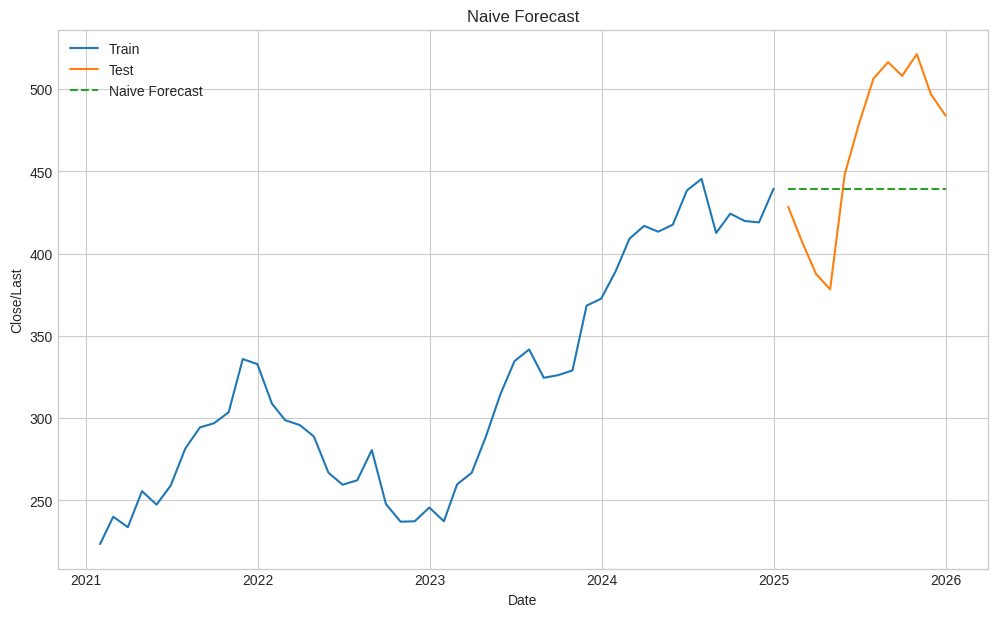

In [442]:
plt.figure(figsize=(12,7))
plt.plot(train['Close'], label='Train') 
plt.plot(test['Close'], label='Test') 
plt.plot(naive_test_forecast, label='Naive Forecast', linestyle='--') 
plt.title("Naive Forecast") 
plt.xlabel("Date") 
plt.ylabel("Close/Last")
plt.legend()
plt.show()

In [443]:
naive_df = pd.DataFrame([naive_metrics]).assign(Method='Naive')

**Average Historical method**

In [444]:
month_means = train.groupby(train.index.month)["Close"].mean()
historical_avg_test_forecast = pd.Series([month_means.loc[d.month] for d in test.index], index=test.index)

In [445]:
historical_avg_test_forecast

Date
2025-01-31    289.724917
2025-02-28    301.871921
2025-03-31    303.239005
2025-04-30    311.573797
2025-05-31    311.543182
2025-06-30    322.880248
2025-07-31    332.686743
2025-08-31    327.974293
2025-09-30    323.714821
2025-10-31    322.319564
2025-11-30    340.107446
2025-12-31    347.609170
Freq: ME, dtype: float64

In [446]:
historical_metrics = accuracy_metrics(test['Close'], historical_avg_test_forecast)
print(historical_metrics)

{'MAE': 143.85500481182783, 'RMSE': np.float64(149.2221178252594), 'MAPE': np.float64(30.47552275682181)}


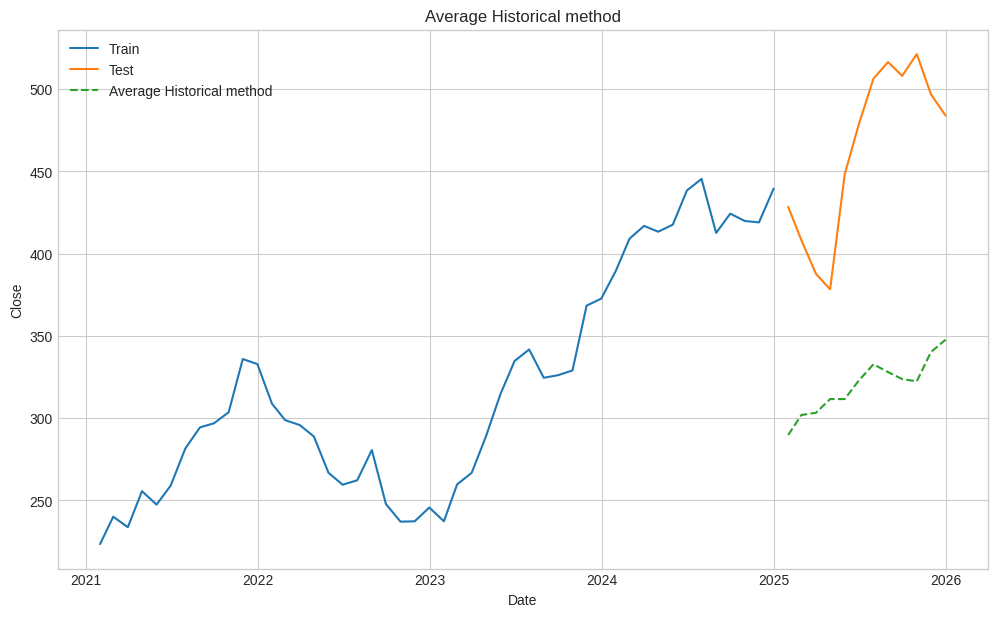

In [447]:
plt.figure(figsize=(12,7))
plt.plot(train['Close'], label='Train') 
plt.plot(test['Close'], label='Test') 
plt.plot(historical_avg_test_forecast, label='Average Historical method', linestyle='--') 
plt.title("Average Historical method") 
plt.xlabel("Date") 
plt.ylabel("Close")
plt.legend()
plt.show()

In [448]:
historical_df = pd.DataFrame([historical_metrics]).assign(Method='Average Historical')

**Simple Average method**

In [449]:
avg_simp_test_forecast = pd.Series(train["Close"].mean(), index=test.index)

In [450]:
avg_simp_test_forecast

Date
2025-01-31    319.603759
2025-02-28    319.603759
2025-03-31    319.603759
2025-04-30    319.603759
2025-05-31    319.603759
2025-06-30    319.603759
2025-07-31    319.603759
2025-08-31    319.603759
2025-09-30    319.603759
2025-10-31    319.603759
2025-11-30    319.603759
2025-12-31    319.603759
Freq: ME, dtype: float64

In [451]:
simple_metrics = accuracy_metrics(test['Close'], avg_simp_test_forecast)
print(simple_metrics)

{'MAE': 143.8550048118278, 'RMSE': np.float64(152.08859699817359), 'MAPE': np.float64(30.198234443863942)}


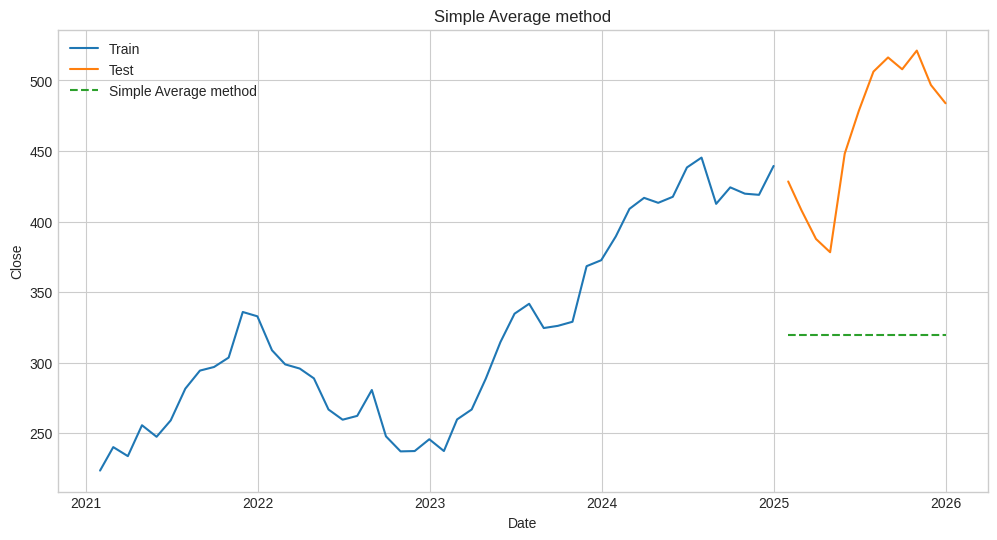

In [452]:
plt.figure(figsize=(12,6))
plt.plot(train['Close'], label='Train') 
plt.plot(test['Close'], label='Test') 
plt.plot(avg_simp_test_forecast, label='Simple Average method', linestyle='--') 
plt.title("Simple Average method") 
plt.xlabel("Date") 
plt.ylabel("Close")
plt.legend()
plt.show()

In [453]:
simple_df = pd.DataFrame([simple_metrics]).assign(Method='Simple Average')

**Simple Exponential Smoothing (SES)**

In [454]:
ses_model = SimpleExpSmoothing(train).fit(smoothing_level=0.4, optimized=False)
ses_test_forecast = pd.Series(ses_model.forecast(len(test)), index=test.index)

In [455]:
ses_test_forecast

Date
2025-01-31    428.282784
2025-02-28    428.282784
2025-03-31    428.282784
2025-04-30    428.282784
2025-05-31    428.282784
2025-06-30    428.282784
2025-07-31    428.282784
2025-08-31    428.282784
2025-09-30    428.282784
2025-10-31    428.282784
2025-11-30    428.282784
2025-12-31    428.282784
Freq: ME, dtype: float64

In [456]:
ses_metrics = accuracy_metrics(test['Close'], ses_test_forecast)
print(ses_metrics)

{'MAE': 53.6553794904824, 'RMSE': np.float64(60.61376494786767), 'MAPE': np.float64(11.23976595650983)}


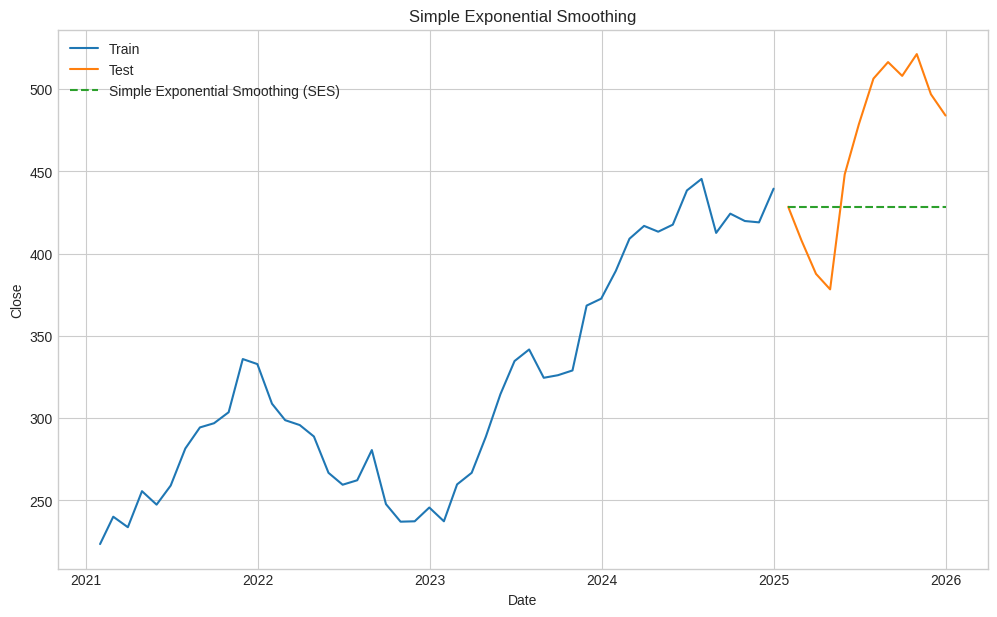

In [457]:
plt.figure(figsize=(12,7))
plt.plot(train['Close'], label='Train') 
plt.plot(test['Close'], label='Test') 
plt.plot(ses_test_forecast, label='Simple Exponential Smoothing (SES)', linestyle='--') 
plt.title("Simple Exponential Smoothing") 
plt.xlabel("Date") 
plt.ylabel("Close")
plt.legend()
plt.show()

In [458]:
ses_df = pd.DataFrame([ses_metrics]).assign(Method='Simple Exponential Smoothing (SES)')

**Holt Linear Trend**

In [459]:
holt_linear_trend = Holt(train["Close"], exponential=False, initialization_method="estimated").fit()
holt_test_forecast = holt_linear_trend.forecast(len(test))

In [460]:
holt_test_forecast

2025-01-31    444.003931
2025-02-28    448.599291
2025-03-31    453.194651
2025-04-30    457.790011
2025-05-31    462.385371
2025-06-30    466.980732
2025-07-31    471.576092
2025-08-31    476.171452
2025-09-30    480.766812
2025-10-31    485.362172
2025-11-30    489.957532
2025-12-31    494.552892
Freq: ME, dtype: float64

In [461]:
holt_linear_metrics = accuracy_metrics(test['Close'], holt_test_forecast)
print(holt_linear_metrics)

{'MAE': 31.872092042814412, 'RMSE': np.float64(38.56784138813358), 'MAPE': np.float64(7.296464872590009)}


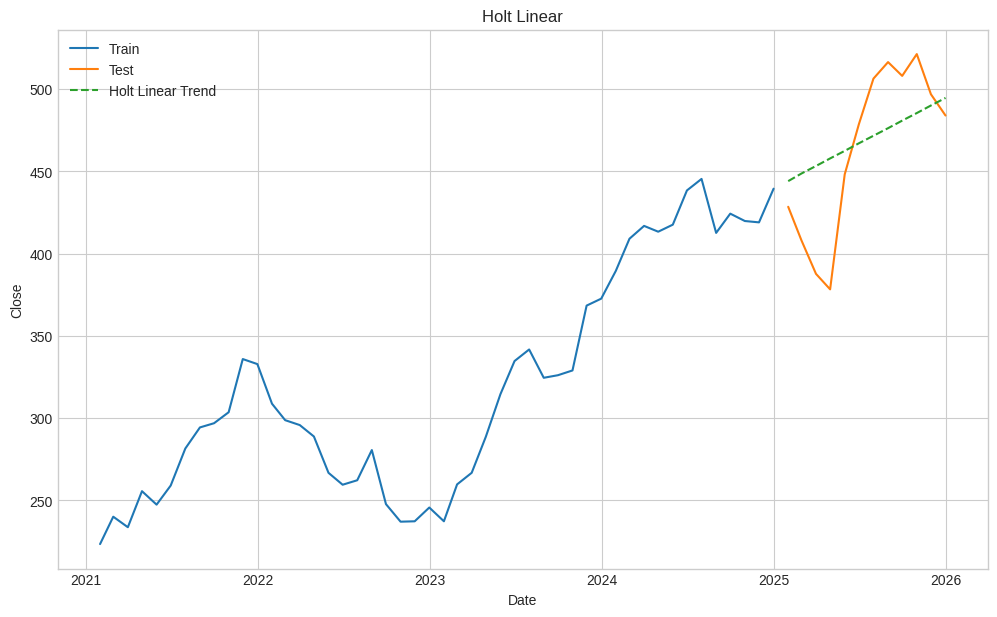

In [462]:
plt.figure(figsize=(12,7))
plt.plot(train['Close'], label='Train') 
plt.plot(test['Close'], label='Test') 
plt.plot(holt_test_forecast, label='Holt Linear Trend', linestyle='--') 
plt.title("Holt Linear") 
plt.xlabel("Date") 
plt.ylabel("Close")
plt.legend()
plt.grid(True) 
plt.show()

In [463]:
holt_linear_df = pd.DataFrame([holt_linear_metrics]).assign(Method='Holt Linear Trend')

**Holt Winters Additive model**

In [464]:
hw_add_model = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit(optimized=True)
hw_add_test_forecast = hw_add_model.forecast(len(test))

In [465]:
hw_add_test_forecast

2025-01-31    434.222351
2025-02-28    446.370003
2025-03-31    447.737986
2025-04-30    456.075858
2025-05-31    456.045542
2025-06-30    467.382455
2025-07-31    477.189475
2025-08-31    472.475819
2025-09-30    468.215905
2025-10-31    466.818974
2025-11-30    484.606382
2025-12-31    492.107849
Freq: ME, dtype: float64

In [466]:
hw_add_metrics = accuracy_metrics(test['Close'], hw_add_test_forecast)
print(hw_add_metrics)

{'MAE': 32.38536050419359, 'RMSE': np.float64(39.66571535985191), 'MAPE': np.float64(7.298003296060067)}


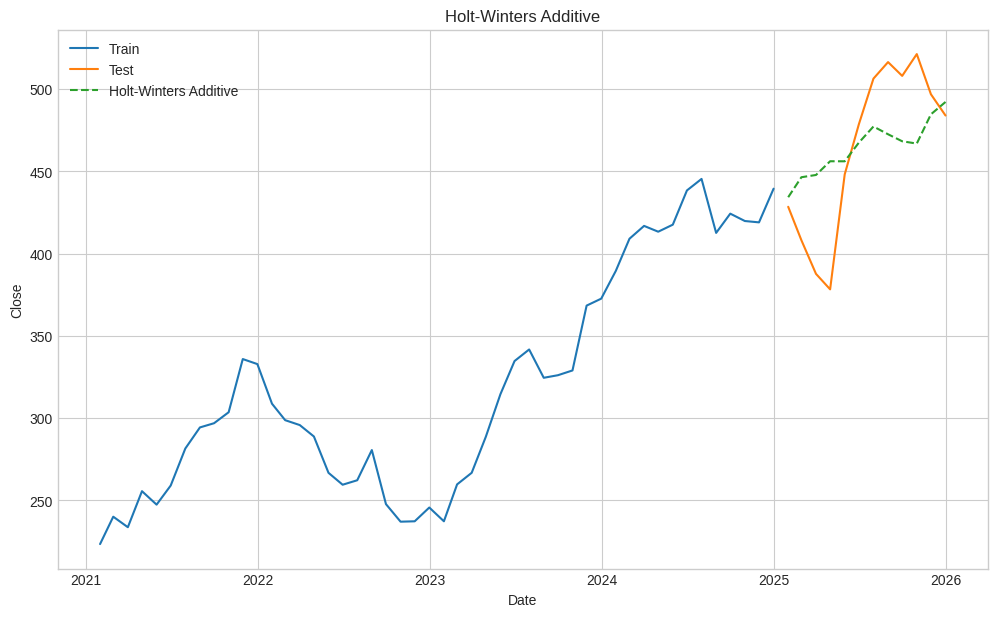

In [467]:
plt.figure(figsize=(12,7))
plt.plot(train['Close'], label='Train') 
plt.plot(test['Close'], label='Test') 
plt.plot(hw_add_test_forecast, label='Holt‑Winters Additive', linestyle='--') 
plt.title("Holt‑Winters Additive") 
plt.xlabel("Date") 
plt.ylabel("Close")
plt.legend()
plt.grid(True) 
plt.show()

In [468]:
hw_add_df = pd.DataFrame([hw_add_metrics]).assign(Method='Holt Winters Additive model')

**Holt Winters multiplicative model**

In [469]:
hw_mul_model = ExponentialSmoothing(train, trend="mul", seasonal="mul", seasonal_periods=12).fit(optimized=True)
hw_mul_test_forecast = hw_mul_model.forecast(len(test))

In [470]:
hw_mul_test_forecast

2025-01-31    434.053420
2025-02-28    450.712374
2025-03-31    453.774712
2025-04-30    462.497470
2025-05-31    463.374488
2025-06-30    481.620624
2025-07-31    494.741624
2025-08-31    481.845319
2025-09-30    478.421258
2025-10-31    476.645582
2025-11-30    501.416094
2025-12-31    512.995766
Freq: ME, dtype: float64

In [471]:
hw_mul_metrics = accuracy_metrics(test['Close'], hw_mul_test_forecast)
print(hw_mul_metrics)

{'MAE': 30.904001272182327, 'RMSE': np.float64(39.384497684402376), 'MAPE': np.float64(7.117962138323889)}


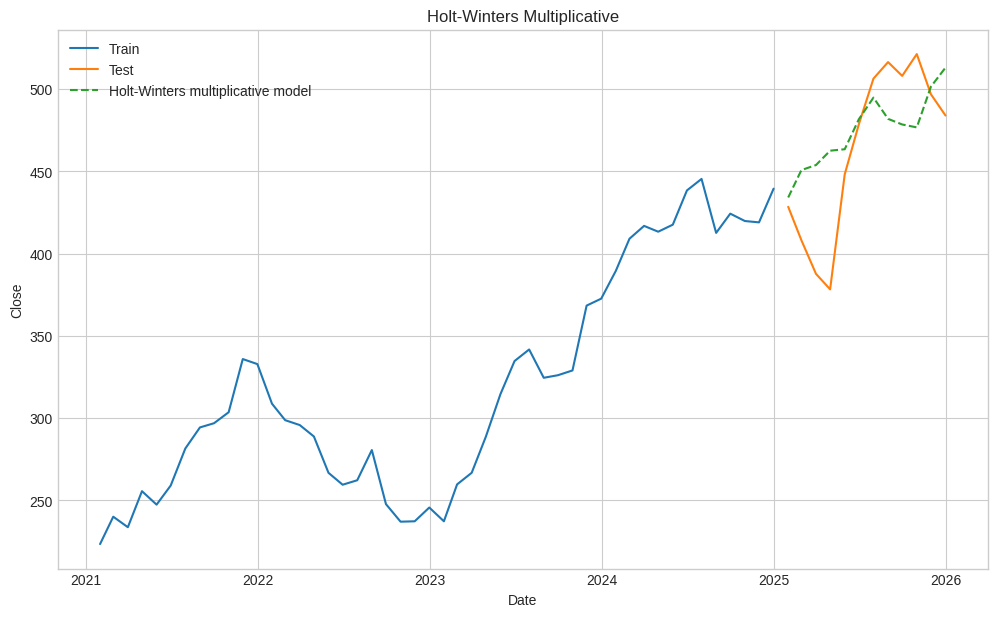

In [472]:
plt.figure(figsize=(12,7))
plt.plot(train['Close'], label='Train') 
plt.plot(test['Close'], label='Test') 
plt.plot(hw_mul_test_forecast, label='Holt‑Winters multiplicative model', linestyle='--') 
plt.title("Holt‑Winters Multiplicative") 
plt.xlabel("Date") 
plt.ylabel("Close")
plt.legend()
plt.grid(True) 
plt.show()

In [473]:
hw_mul_df = pd.DataFrame([hw_mul_metrics]).assign(Method='Holt Winters multiplicative model')

**Putting the forecasts together (for metrics comparison)**

In [474]:
models = {
    "Naive": naive_test_forecast,
    "Simple Average": avg_simp_test_forecast,
    "Average Historical": historical_avg_test_forecast,
    "Simple Exponential Smoothing (SES)": ses_test_forecast,
    "Holt Linear Trend": holt_test_forecast,
    "Holt Winters Additive model": hw_add_test_forecast,
    "Holt Winters multiplicative model": hw_mul_test_forecast
}

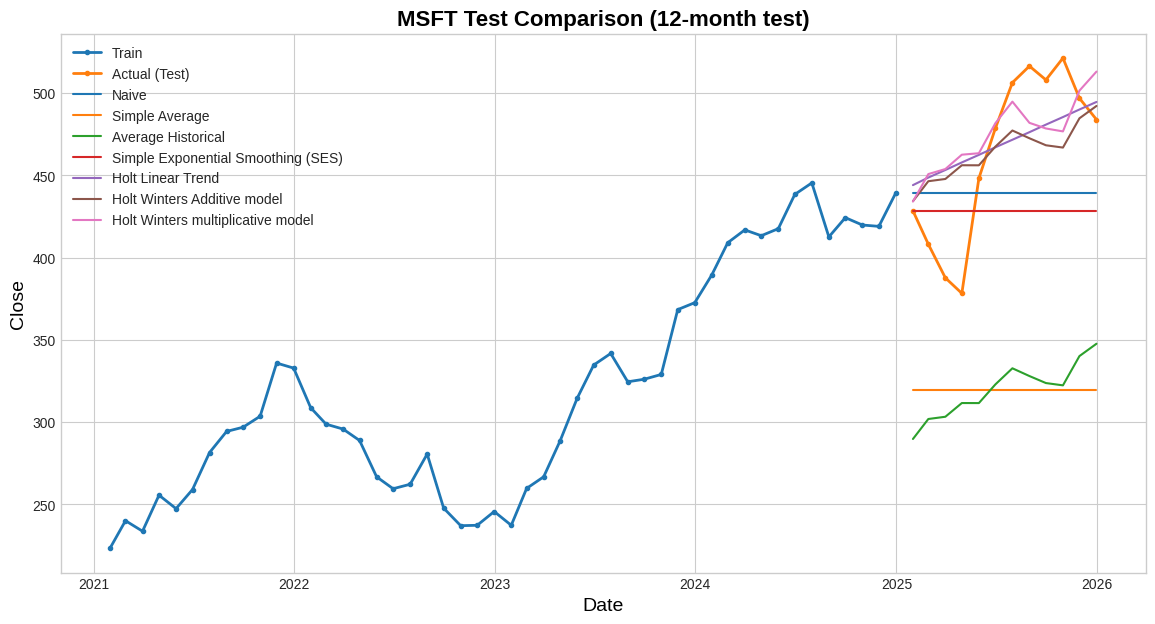

In [475]:
plt.style.available
plt.style.use('seaborn-v0_8-whitegrid')
plt.figure(figsize=(14,7), dpi=100)
plt.plot(train.index, train, label="Train", linewidth=2, color="tab:blue", marker="o", markersize=3)
plt.plot(test.index, test, label="Actual (Test)", linewidth=2, color="tab:orange", marker="o", markersize=3)


for name, fc in models.items():
    fc = pd.Series(fc, index=test.index)
    plt.plot(test.index, fc, label=name)

plt.title ('MSFT Test Comparison (12-month test)', color = 'black', fontdict= {'fontweight': 'bold', 'fontstyle' :'normal', 'fontsize' : 16})
plt.xlabel ('Date', color = 'black', fontdict= {'fontweight': 'normal', 'fontstyle' :'normal', 'fontsize' : 14})
plt.ylabel ('Close', color = 'black', fontdict= {'fontweight': 'normal', 'fontstyle' :'normal', 'fontsize' : 14})
plt.legend()
plt.show()

In [476]:
rts_all = pd.concat([naive_df, historical_df, simple_df, ses_df, holt_linear_df, hw_add_df, hw_mul_df], ignore_index=True)
display(rts_all.sort_values(by='MAPE'))

,MAE,RMSE,MAPE,Method
6,30.904001,39.384498,7.117962,Holt Winters multiplicative model
4,31.872092,38.567841,7.296465,Holt Linear Trend
5,32.385361,39.665715,7.298003,Holt Winters Additive model
0,49.926831,54.909841,10.661048,Naive
3,53.655379,60.613765,11.239766,Simple Exponential Smoothing (SES)
2,143.855005,152.088597,30.198234,Simple Average
1,143.855005,149.222118,30.475523,Average Historical


# Activity 2

**ADF test**

In [477]:
adf_test = adfuller(df_m['Close'])
print('ADF Test: p-value =%f' % adf_test[1])

kpss_test = kpss(train['Close'])
print('KPSS Test: p-value =%f' % kpss_test[1])

ADF Test: p-value =0.806756
KPSS Test: p-value =0.010000


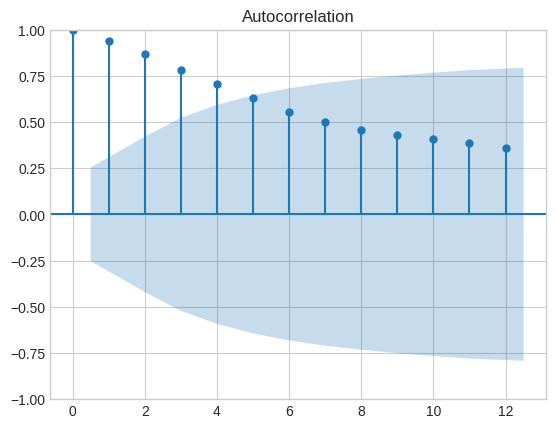

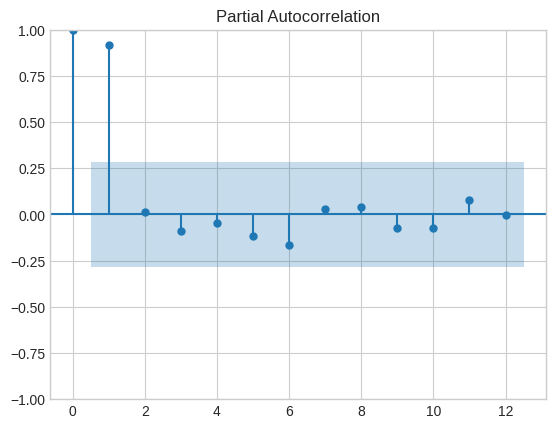

In [478]:
plot_acf(df_m['Close'], lags=12);
plot_pacf(train['Close'], lags=12);

**1st Order Differencing**

In [479]:
train_diff1 = df_m['Close'].diff().dropna()

adf_test_diff1 = adfuller(train_diff1)
print('ADF Test (Diff 1): p-value = %f' % adf_test_diff1[1])


kpss_test_diff1 = kpss(train_diff1, regression='c', nlags='auto')
print('KPSS Test (Diff 1): p-value = %f' % kpss_test_diff1[1])

ADF Test (Diff 1): p-value = 0.000000
KPSS Test (Diff 1): p-value = 0.100000


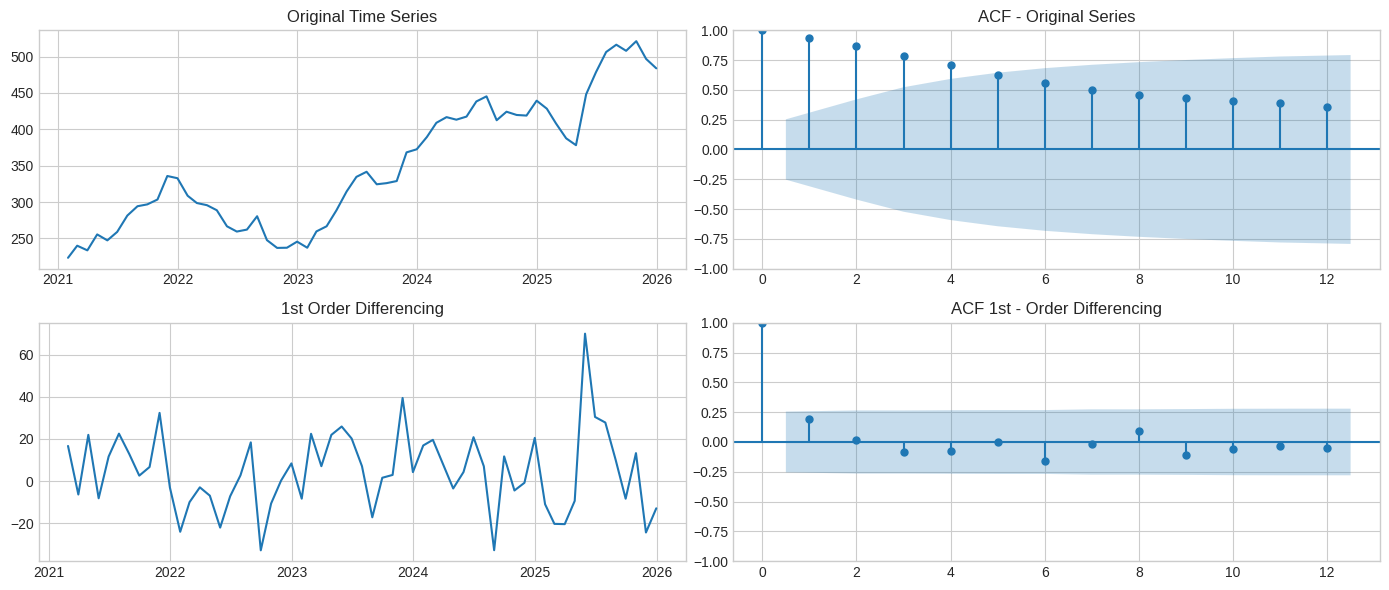

In [480]:
train_diff1 = df_m["Close"].dropna().diff(1).dropna()
fig, axes = plt.subplots(2,2, figsize=(14,6))

axes[0,0].plot(df_m["Close"].dropna().index, df_m["Close"].dropna().values)
axes[0,0].set_title("Original Time Series")

plot_acf(df_m["Close"].dropna(),lags=12,ax=axes[0,1])
axes[0,1].set_title("ACF - Original Series")

axes[1,0].plot(train_diff1.index,train_diff1.values)
axes[1,0].set_title("1st Order Differencing")

plot_acf(train_diff1,lags=12, ax=axes[1,1])
axes[1,1].set_title("ACF 1st - Order Differencing")

plt.tight_layout()
plt.show()

**2nd Order Differencing**

In [481]:
train_diff2 = df_m['Close'].diff().diff().dropna()

adf_test_diff2 = adfuller(train_diff2)
print('ADF Test (Diff 2): p-value = %f' % adf_test_diff1[1])

ADF Test (Diff 2): p-value = 0.000000


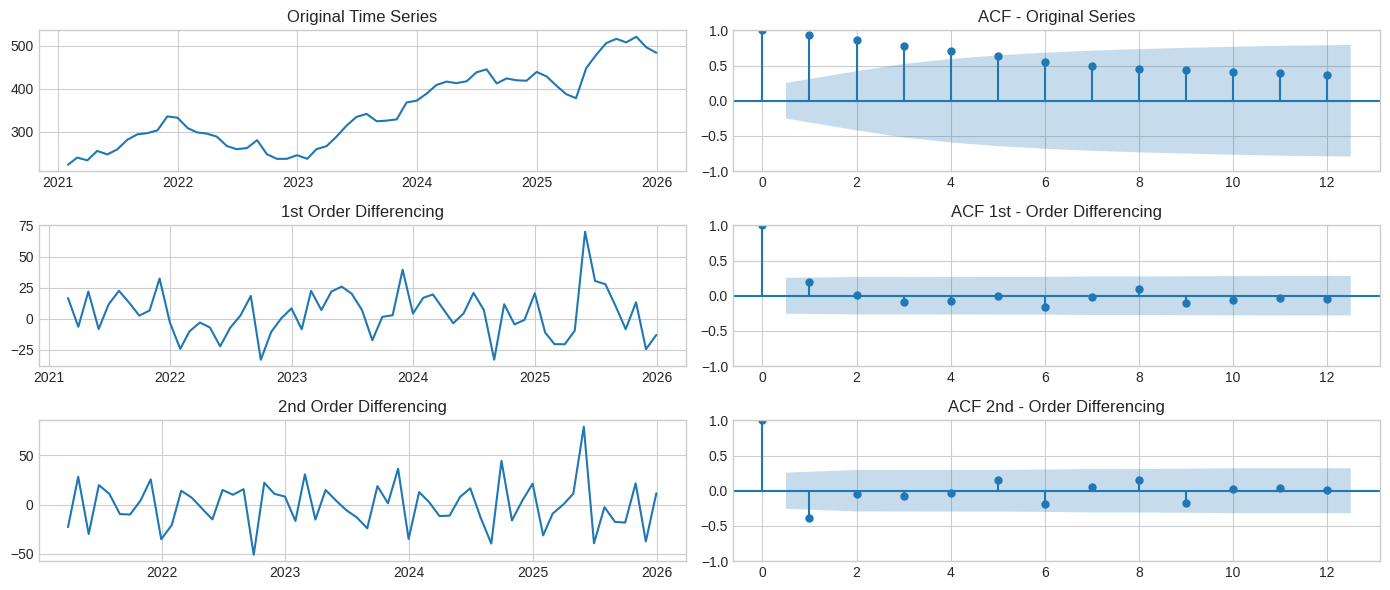

In [482]:
train_diff1 = df_m["Close"].dropna().diff(1).dropna()
train_diff2 = df_m['Close'].diff().diff().dropna()
fig, axes = plt.subplots(3,2, figsize=(14,6))


axes[0,0].plot(df_m["Close"].dropna().index, df_m["Close"].dropna().values)
axes[0,0].set_title("Original Time Series")


plot_acf(df_m["Close"].dropna(),lags=12,ax=axes[0,1])
axes[0,1].set_title("ACF - Original Series")


axes[1,0].plot(train_diff1.index,train_diff1.values)
axes[1,0].set_title("1st Order Differencing")


plot_acf(train_diff1,lags=12, ax=axes[1,1])
axes[1,1].set_title("ACF 1st - Order Differencing")

axes[2,0].plot(train_diff2.index,train_diff2.values)
axes[2,0].set_title("2nd Order Differencing")


plot_acf(train_diff2,lags=12, ax=axes[2,1])
axes[2,1].set_title("ACF 2nd - Order Differencing")

plt.tight_layout()
plt.show()

<Figure size 1000x400 with 0 Axes>

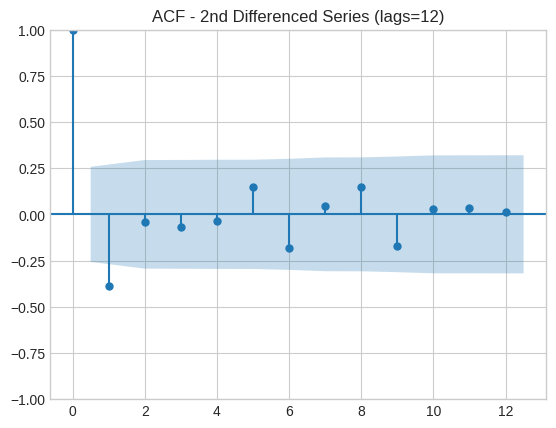

<Figure size 1000x400 with 0 Axes>

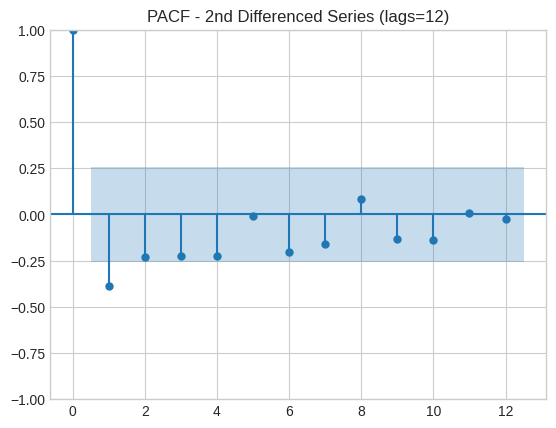

In [483]:
plt.figure(figsize=(10,4))
plot_acf(train_diff2, lags=12)
plt.title("ACF - 2nd Differenced Series (lags=12)")
plt.show()

plt.figure(figsize=(10,4))
plot_pacf(train_diff2, lags=12)
plt.title("PACF - 2nd Differenced Series (lags=12)")
plt.show()

In [484]:
# (1,1,0)
model=ARIMA(df_m["Close"], order=(1,1,0))
model_fit=model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                   60
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -255.803
Date:                Wed, 28 Jan 2026   AIC                            515.605
Time:                        11:31:34   BIC                            519.760
Sample:                    01-31-2021   HQIC                           517.227
                         - 12-31-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2409      0.180      1.335      0.182      -0.113       0.595
sigma2       341.1793     45.522      7.495      0.000     251.958     430.400
Ljung-Box (L1) (Q):                   0.08   Jarque-

In [485]:
# (1,1,0)
model=ARIMA(df_m["Close"], order=(1,1,0))
model_fit=model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                   60
Model:                 ARIMA(1, 1, 0)   Log Likelihood                -255.803
Date:                Wed, 28 Jan 2026   AIC                            515.605
Time:                        11:31:34   BIC                            519.760
Sample:                    01-31-2021   HQIC                           517.227
                         - 12-31-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2409      0.180      1.335      0.182      -0.113       0.595
sigma2       341.1793     45.522      7.495      0.000     251.958     430.400
Ljung-Box (L1) (Q):                   0.08   Jarque-

In [486]:
# (0,1,1)
model=ARIMA(df_m["Close"], order=(0,1,1))
model_fit=model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                   60
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -255.977
Date:                Wed, 28 Jan 2026   AIC                            515.954
Time:                        11:31:34   BIC                            520.109
Sample:                    01-31-2021   HQIC                           517.576
                         - 12-31-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.2177      0.175      1.247      0.213      -0.125       0.560
sigma2       343.2628     44.349      7.740      0.000     256.341     430.185
Ljung-Box (L1) (Q):                   0.02   Jarque-

In [487]:
warnings.filterwarnings("ignore")

y = df_m["Close"]

p_range = (0, 1)
q_range = (0, 1, 2)
d = 2

results = []

for p in p_range:
    for q in q_range:
        try:
            model = sm.tsa.arima.ARIMA(y, order=(p, d, q))
            fit = model.fit()
            results.append({
                "p": p, "d": d, "q": q,
                "AIC": fit.aic,
                #"BIC": fit.bic
            })
        except:
            continue

results_df = pd.DataFrame(results).sort_values("AIC").reset_index(drop=True)

print("ARIMA(p,1,q) models by AIC:")
print(results_df)

best = results_df.iloc[0]
best_order = (int(best["p"]), int(best["d"]), int(best["q"]))
print("\nBest ARIMA order by AIC:", best_order, "AIC:", best["AIC"])

ARIMA(p,1,q) models by AIC:
   p  d  q         AIC
0  1  2  1  511.501260
1  0  2  2  511.653761
2  0  2  1  512.259416
3  1  2  2  513.500332
4  1  2  0  525.276847
5  0  2  0  532.872894

Best ARIMA order by AIC: (1, 2, 1) AIC: 511.50125977047617


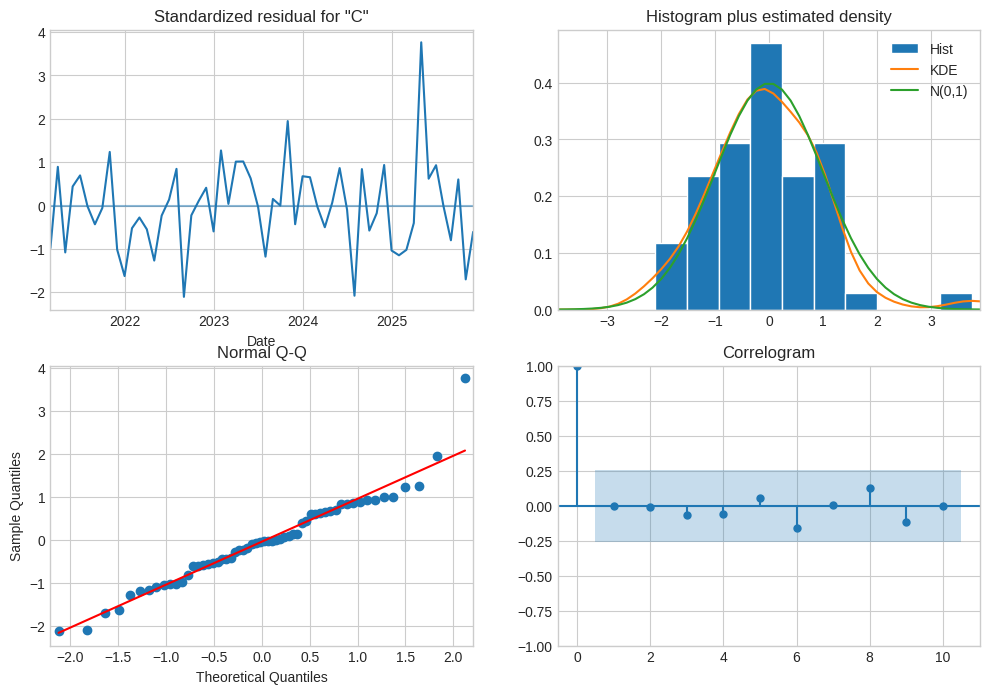

In [488]:
#Plotting diagnostics for the best ARIMA order by AIC
model=ARIMA(df_m["Close"], order= (1, 2, 1))
model_fit=model.fit()
model_fit.plot_diagnostics(figsize=(12,8))
plt.show()

In [489]:
# (1, 2, 1)
model=ARIMA(train["Close"], order= (1, 2, 1))
model_fit=model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                   48
Model:                 ARIMA(1, 2, 1)   Log Likelihood                -194.096
Date:                Wed, 28 Jan 2026   AIC                            394.191
Time:                        11:31:35   BIC                            399.677
Sample:                    01-31-2021   HQIC                           396.246
                         - 12-31-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1373      0.194      0.708      0.479      -0.243       0.517
ma.L1         -0.9983      2.394     -0.417      0.677      -5.690       3.693
sigma2       250.8125    600.451      0.418      0.6

In [490]:
arima_forecast = model_fit.forecast(steps=len(test))
arima_forecast = pd.Series(arima_forecast, index=test.index)

print(arima_forecast)

Date
2025-01-31    446.266845
2025-02-28    451.256054
2025-03-31    455.988676
2025-04-30    460.686072
2025-05-31    465.378633
2025-06-30    470.070530
2025-07-31    474.762335
2025-08-31    479.454129
2025-09-30    484.145920
2025-10-31    488.837711
2025-11-30    493.529503
2025-12-31    498.221294
Freq: ME, Name: predicted_mean, dtype: float64


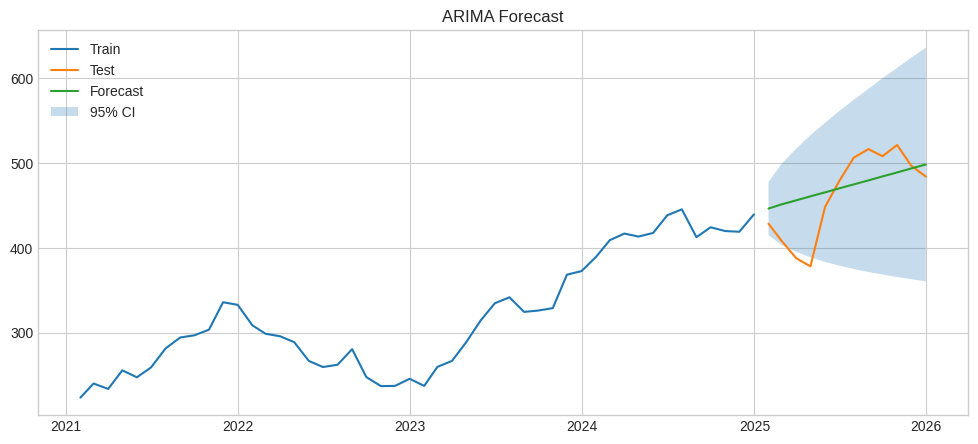

In [491]:
forecast_res = model_fit.get_forecast(steps=len(test))
forecast_mean = forecast_res.predicted_mean
forecast_coeficent = forecast_res.conf_int().values

forecast_mean = pd.Series(forecast_mean.values, index=test.index)

plt.figure(figsize=(12,5))
plt.plot(train.index, train["Close"], label="Train")
plt.plot(test.index, test["Close"], label="Test")
plt.plot(forecast_mean.index,forecast_mean.values, label="Forecast")
plt.fill_between(
    forecast_mean.index,
    forecast_coeficent[:,0],
    forecast_coeficent[:,1],
    alpha = 0.25,
    label = "95% CI"
)

plt.title("ARIMA Forecast")
plt.legend()
plt.show()

In [492]:
arima_rmse = np.sqrt(mean_squared_error(test['Close'], arima_forecast)).round(2)
arima_mape = np.round(np.mean(np.abs(test['Close'] - arima_forecast) / test['Close']) * 100, 2)
arima_mae = np.round(np.mean(np.abs(test['Close'] - arima_forecast)), 2)

arima = pd.DataFrame({'Method': "ARIMA", 'RMSE': [arima_rmse], 'MAE': [arima_mae], 'MAPE': [arima_mape]})
arima

,Method,RMSE,MAE,MAPE
0,ARIMA,38.95,31.65,7.31


**SARIMA Model**

In [493]:
s = 12  # seasonal period
train_seas_diff1 = df_m['Close'].diff(s).dropna()

<Figure size 1000x400 with 0 Axes>

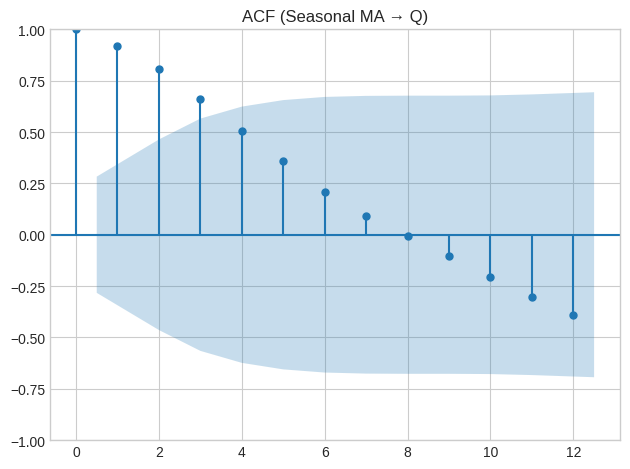

<Figure size 1000x400 with 0 Axes>

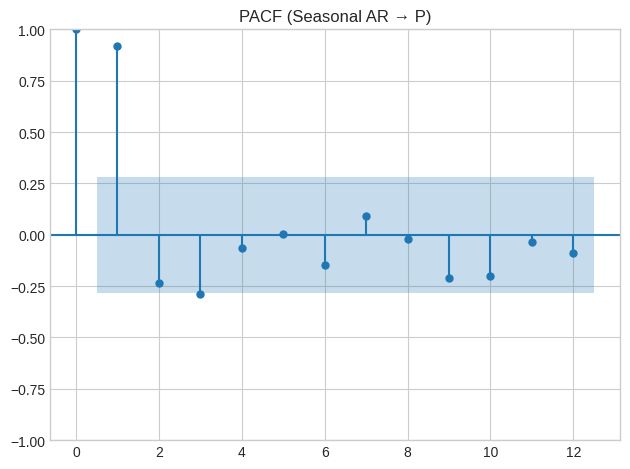

In [494]:
plt.figure(figsize=(10,4))
sm.graphics.tsa.plot_acf(train_seas_diff1, lags=s)

plt.title("ACF (Seasonal MA → Q)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10,4))
sm.graphics.tsa.plot_pacf(train_seas_diff1, lags=s)

plt.title("PACF (Seasonal AR → P)")
plt.tight_layout()
plt.show()

In [495]:
sarima_model = SARIMAX(df_m["Close"], order =  (1, 2, 1), seasonal_order = (0,1,1,12))
sarimamodel_2 = sarima_model.fit()
print(sarimamodel_2.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Close   No. Observations:                   60
Model:             SARIMAX(1, 2, 1)x(0, 1, 1, 12)   Log Likelihood                -211.576
Date:                            Wed, 28 Jan 2026   AIC                            431.152
Time:                                    11:31:37   BIC                            438.467
Sample:                                01-31-2021   HQIC                           433.893
                                     - 12-31-2025                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2314      0.226      1.025      0.305      -0.211       0.674
ma.L1         -0.9992     14.753   

In [496]:
sarima_model = SARIMAX(df_m["Close"], order =  (1, 2, 1), seasonal_order = (1,1,1,12))
sarimamodel_2 = sarima_model.fit()
print(sarimamodel_2.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Close   No. Observations:                   60
Model:             SARIMAX(1, 2, 1)x(1, 1, 1, 12)   Log Likelihood                -211.376
Date:                            Wed, 28 Jan 2026   AIC                            432.751
Time:                                    11:31:37   BIC                            441.894
Sample:                                01-31-2021   HQIC                           436.176
                                     - 12-31-2025                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2258      0.224      1.007      0.314      -0.213       0.665
ma.L1         -0.9997     45.600   

In [497]:
warnings.filterwarnings("ignore")

p_range = (0, 1)
q_range = (0, 1, 2)
d = 2
Q_range = (0, 1, 2)
P_range = (0, 1)
D = 1
m = s

results = []
best_aic = float('inf')
best_order = None
best_seasonal_order = None

for p in p_range:
    for q in q_range:
        for P in P_range:
            for Q in Q_range:
                order = (p, d, q)
                seasonal_order = (P, D, Q, m)
                try:
                    model = SARIMAX(train['Close'],
                                      order=order,
                                      seasonal_order=seasonal_order,
                                      enforce_stationarity=False,
                                      enforce_invertibility=False)
                    model_fit = model.fit(disp=False)
                    aic = model_fit.aic

                    if aic < best_aic:
                        best_aic = aic
                        best_order = order
                        best_seasonal_order = seasonal_order

                    print(f'SARIMA{order}{seasonal_order} AIC: {aic:.2f}')

                except Exception as e:
                    continue

print(f"\nBest SARIMA order by AIC: {best_order}{best_seasonal_order} with AIC: {best_aic:.2f}")

SARIMA(0, 2, 0)(0, 1, 0, 12) AIC: 316.13
SARIMA(0, 2, 0)(0, 1, 1, 12) AIC: 202.70
SARIMA(0, 2, 0)(0, 1, 2, 12) AIC: 90.79
SARIMA(0, 2, 0)(1, 1, 0, 12) AIC: 210.72
SARIMA(0, 2, 0)(1, 1, 1, 12) AIC: 200.79
SARIMA(0, 2, 0)(1, 1, 2, 12) AIC: 91.91
SARIMA(0, 2, 1)(0, 1, 0, 12) AIC: 295.58
SARIMA(0, 2, 1)(0, 1, 1, 12) AIC: 184.86
SARIMA(0, 2, 1)(0, 1, 2, 12) AIC: 78.08
SARIMA(0, 2, 1)(1, 1, 0, 12) AIC: 200.17
SARIMA(0, 2, 1)(1, 1, 1, 12) AIC: 181.35
SARIMA(0, 2, 1)(1, 1, 2, 12) AIC: 77.96
SARIMA(0, 2, 2)(0, 1, 0, 12) AIC: 289.36
SARIMA(0, 2, 2)(0, 1, 1, 12) AIC: 174.26
SARIMA(0, 2, 2)(0, 1, 2, 12) AIC: 67.13
SARIMA(0, 2, 2)(1, 1, 0, 12) AIC: 202.17
SARIMA(0, 2, 2)(1, 1, 1, 12) AIC: 173.84
SARIMA(0, 2, 2)(1, 1, 2, 12) AIC: 65.55
SARIMA(1, 2, 0)(0, 1, 0, 12) AIC: 306.42
SARIMA(1, 2, 0)(0, 1, 1, 12) AIC: 199.57
SARIMA(1, 2, 0)(0, 1, 2, 12) AIC: 90.56
SARIMA(1, 2, 0)(1, 1, 0, 12) AIC: 199.25
SARIMA(1, 2, 0)(1, 1, 1, 12) AIC: 198.61
SARIMA(1, 2, 0)(1, 1, 2, 12) AIC: 91.99
SARIMA(1, 2, 1)(0, 1, 0,

In [498]:
best_sarima_model_by_AIC = SARIMAX(train['Close'],
                                order=best_order,
                                seasonal_order=best_seasonal_order,
                                enforce_stationarity=False,
                                enforce_invertibility=False)
best_sarima_model_by_AIC_fit = best_sarima_model_by_AIC.fit(disp=False)

print(best_sarima_model_by_AIC_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Close   No. Observations:                   48
Model:             SARIMAX(0, 2, 2)x(1, 1, 2, 12)   Log Likelihood                 -26.773
Date:                            Wed, 28 Jan 2026   AIC                             65.546
Time:                                    11:31:52   BIC                             65.221
Sample:                                01-31-2021   HQIC                            61.535
                                     - 12-31-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -1.9925    323.032     -0.006      0.995    -635.124     631.139
ma.L2          0.9996    324.260   

In [499]:
model = SARIMAX(
    train['Close'],
    order=(0,2,2),
    seasonal_order=(1,1,2,12),
    trend='n',
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fity= model.fit(method='lbfgs', maxiter=2000, disp=False)
print(model_fity.summary())

                                     SARIMAX Results                                      
Dep. Variable:                              Close   No. Observations:                   48
Model:             SARIMAX(0, 2, 2)x(1, 1, 2, 12)   Log Likelihood                 -26.773
Date:                            Wed, 28 Jan 2026   AIC                             65.546
Time:                                    11:31:53   BIC                             65.221
Sample:                                01-31-2021   HQIC                            61.535
                                     - 12-31-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -1.9928   1823.263     -0.001      0.999   -3575.522    3571.537
ma.L2          0.9999   1830.161   

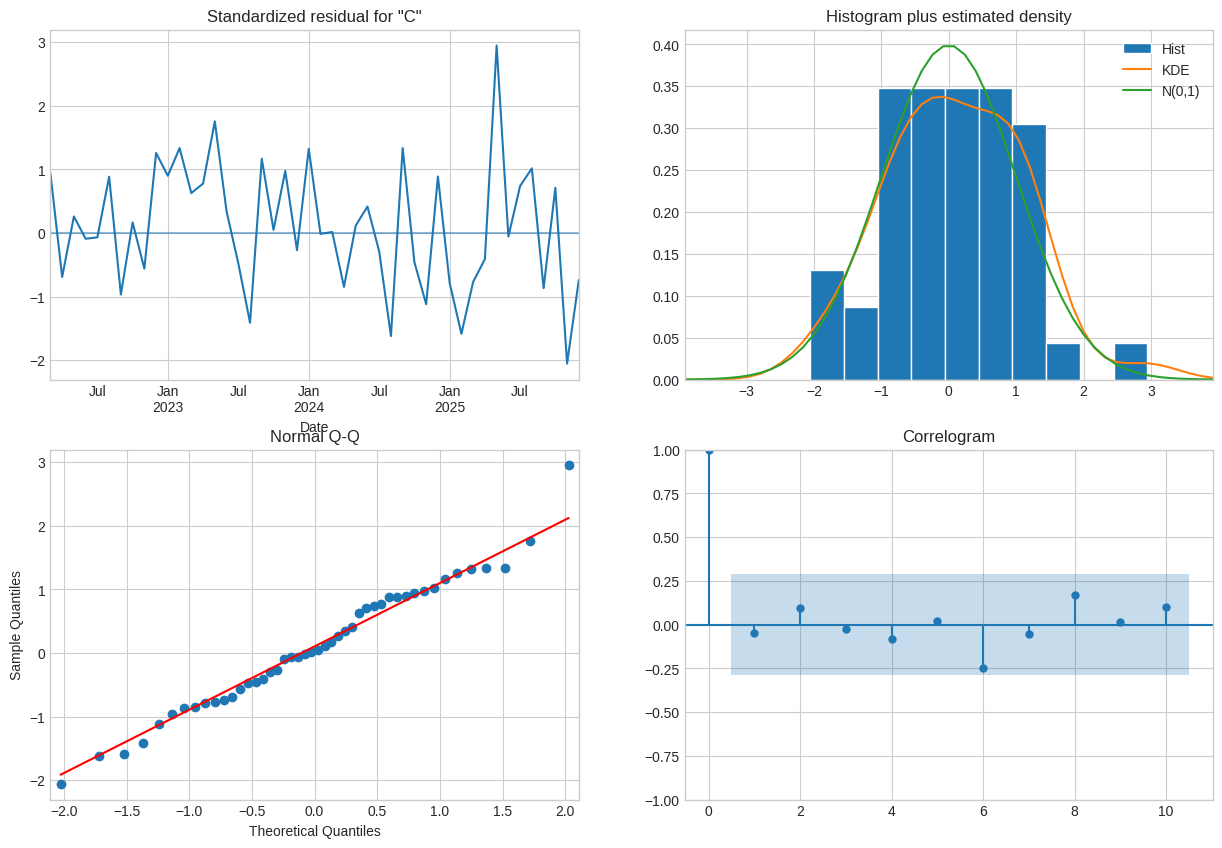

In [500]:
sarimamodel_2.plot_diagnostics(figsize=(15, 10))
plt.show()

In [501]:
start_index = len(train)
end_index = len(df_m) - 1

sarima_forecast = best_sarima_model_by_AIC_fit.predict(start=start_index, end=end_index)

# Creating a DataFrame for the SARIMA forecast results
sarima_display = test.copy()
sarima_display['SARIMA_forecast'] = sarima_forecast.values

display(sarima_display.round(2))

,Close,SARIMA_forecast
Date,,
2025-01-31,428.40,469.39
2025-02-28,408.09,514.78
2025-03-31,387.65,528.08
2025-04-30,378.23,539.85
2025-05-31,448.14,560.66
2025-06-30,478.55,600.57
2025-07-31,506.29,619.90
2025-08-31,516.33,573.12
2025-09-30,507.95,615.21


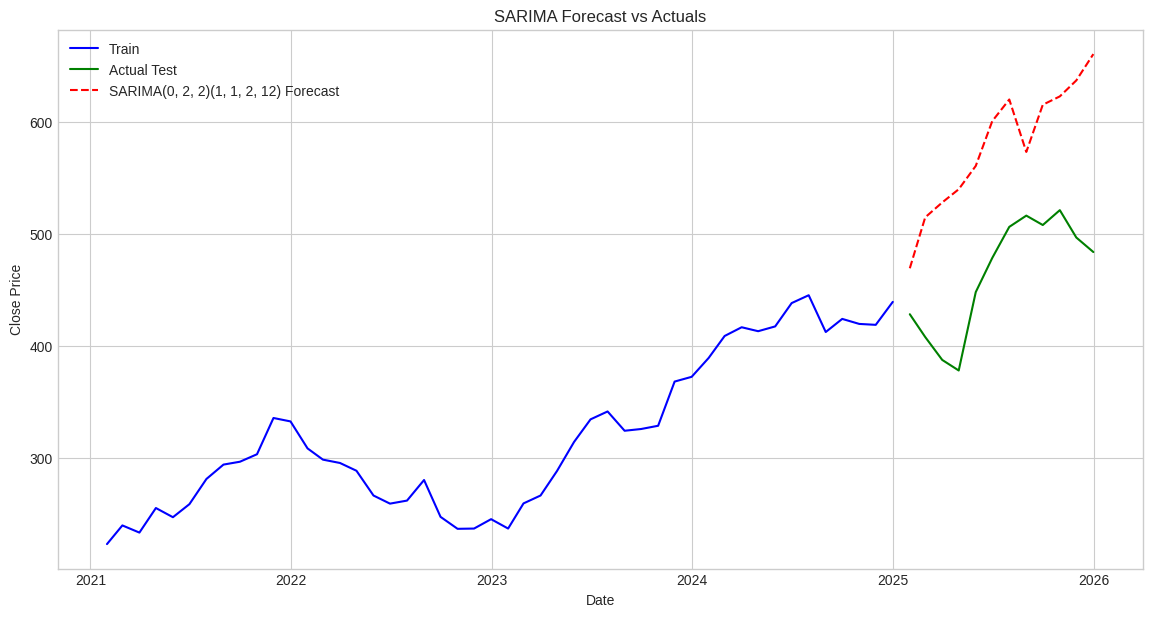

In [502]:
plt.figure(figsize=(14,7))
plt.plot(train['Close'], label='Train', color='blue')
plt.plot(test['Close'], label='Actual Test', color='green')
plt.plot(sarima_display['SARIMA_forecast'], label=f'SARIMA{best_order}{best_seasonal_order} Forecast', color='red', linestyle='--')
plt.title('SARIMA Forecast vs Actuals')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [503]:
sarima_rmse = np.sqrt(mean_squared_error(test['Close'], sarima_display['SARIMA_forecast'])).round(2)
sarima_mae = np.round(np.mean(np.abs(test['Close'] - sarima_display['SARIMA_forecast'])), 2)
sarima_mape = np.round(np.mean(np.abs(test['Close'] - sarima_display['SARIMA_forecast']) / test['Close']) * 100, 2)

sarima = pd.DataFrame({'Method': "SARIMA", 'RMSE': [sarima_rmse], 'MAE': [sarima_mae], 'MAPE': [sarima_mape]})
sarima

,Method,RMSE,MAE,MAPE
0,SARIMA,120.82,115.0,25.33


In [504]:
result = pd.concat([arima,sarima], ignore_index=True)
result

,Method,RMSE,MAE,MAPE
0,ARIMA,38.95,31.65,7.31
1,SARIMA,120.82,115.00,25.33


# Activity 3

**Preparing Data with Lag**

In [505]:
regression_dataframe = df_m.copy()
regression_dataframe['train_diff2'] = train_diff2
regression_dataframe['train_diff2_lag'] = regression_dataframe['train_diff2'].shift(1)
regression_dataframe_cleaned = regression_dataframe.dropna()
a = regression_dataframe_cleaned[['train_diff2_lag']]
b = regression_dataframe_cleaned['train_diff2']
print(regression_dataframe_cleaned.head())

print('\na head:')
print(a.head())

print('\nb head:')
print(b.head())

                 Close  train_diff2  train_diff2_lag
Date                                                
2021-04-30  255.580000    28.298146       -23.032670
2021-05-31  247.395500   -30.090152        28.298146
2021-06-30  259.018409    19.807409       -30.090152
2021-07-31  281.502381    10.861063        19.807409
2021-08-31  294.314091    -9.672262        10.861063

a head:
            train_diff2_lag
Date                       
2021-04-30       -23.032670
2021-05-31        28.298146
2021-06-30       -30.090152
2021-07-31        19.807409
2021-08-31        10.861063

b head:
Date
2021-04-30    28.298146
2021-05-31   -30.090152
2021-06-30    19.807409
2021-07-31    10.861063
2021-08-31    -9.672262
Freq: ME, Name: train_diff2, dtype: float64


**Split Data**

In [506]:
a_train = a.loc[a.index.isin(train.index)]
a_test = a.loc[a.index.isin(test.index)]
b_train = b.loc[b.index.isin(train.index)]
b_test = b.loc[b.index.isin(test.index)]
print(f"Shape of a_train: {a_train.shape}")
print(f"Shape of a_test: {a_test.shape}")
print(f"Shape of b_train: {b_train.shape}")
print(f"Shape of b_test: {b_test.shape}")

print(f"Length of b_test: {len(b_test)}")
print(f"Forecast horizon: {s}")

Shape of a_train: (45, 1)
Shape of a_test: (12, 1)
Shape of b_train: (45,)
Shape of b_test: (12,)
Length of b_test: 12
Forecast horizon: 12


**Linear Regression Model and Forecast**

In [507]:
lr_model = LinearRegression()
lr_model.fit(a_train, b_train)
linear_regression_diff2_forecast = lr_model.predict(a_test)
linear_regression_diff2_forecast_series = pd.Series(linear_regression_diff2_forecast, index=b_test.index)

In [508]:
last_train_diff1_value = train_diff1.loc[train.index[-1]]

linear_regression_diff1_forecast_values = [last_train_diff1_value]
for diff2_val in linear_regression_diff2_forecast_series:
    linear_regression_diff1_forecast_values.append(linear_regression_diff1_forecast_values[-1] + diff2_val)

linear_regression_diff1_forecast_series = pd.Series(linear_regression_diff1_forecast_values[1:], index=test.index)

last_train_close_value = train['Close'].iloc[-1]

linear_regression_forecast_close_values = [last_train_close_value]
for diff1_val in linear_regression_diff1_forecast_series:
    linear_regression_forecast_close_values.append(linear_regression_forecast_close_values[-1] + diff1_val)

linear_regression_forecast_close = pd.Series(linear_regression_forecast_close_values[1:], index=test.index)

linear_fr = test.copy()
linear_fr['Linear_Regression_Forecast'] = linear_regression_forecast_close
print(linear_fr)


                 Close  Linear_Regression_Forecast
Date                                              
2025-01-31  428.402500                  451.010281
2025-02-28  408.090526                  476.787327
2025-03-31  387.650000                  507.056072
2025-04-30  378.231429                  537.808527
2025-05-31  448.137619                  564.174974
2025-06-30  478.549500                  556.325784
2025-07-31  506.292727                  566.152364
2025-08-31  516.332857                  577.571982
2025-09-30  507.952381                  597.150576
2025-10-31  521.203043                  625.201499
2025-11-30  496.798947                  644.233105
2025-12-31  483.863636                  680.137100


**Accuracy Metrics**

In [509]:
lr_rmse = np.sqrt(mean_squared_error(test['Close'], linear_fr['Linear_Regression_Forecast'])).round(2)
lr_mape = np.round(np.mean(np.abs(test['Close'] - linear_fr['Linear_Regression_Forecast']) / test['Close']) * 100, 2)
lr_mae = np.round(np.mean(np.abs(test['Close'] - linear_fr['Linear_Regression_Forecast'])), 2)

lr_results = pd.DataFrame({'Method': ['Linear Regression - AR2 on diff2'], 'RMSE': [lr_rmse], 'MAE': [lr_mae], 'MAPE': [lr_mape]})
lr_results

,Method,RMSE,MAE,MAPE
0,Linear Regression - AR2 on diff2,112.11,101.84,22.39


**Visualization of Linear Regression Forecast**

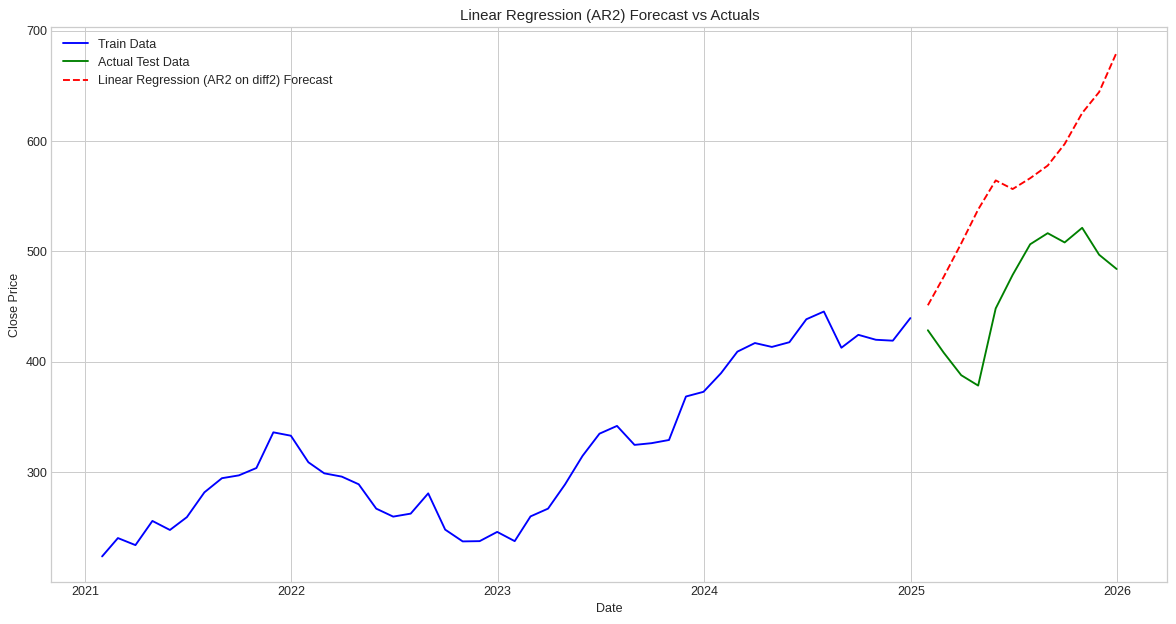

In [510]:
plt.figure(figsize=(16, 8), dpi = 90)
plt.plot(train['Close'], label='Train Data', color='blue')
plt.plot(test['Close'], label='Actual Test Data', color='green')
plt.plot(linear_fr['Linear_Regression_Forecast'], label='Linear Regression (AR2 on diff2) Forecast', color='red', linestyle='--')
plt.title('Linear Regression (AR2) Forecast vs Actuals')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [511]:
a_train_sm = sm.add_constant(a_train)
model = sm.OLS(b_train,a_train_sm)
model_fit = model.fit()
print(model_fit.summary())

                            OLS Regression Results                            
Dep. Variable:            train_diff2   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.173
Method:                 Least Squares   F-statistic:                     10.19
Date:                Wed, 28 Jan 2026   Prob (F-statistic):            0.00264
Time:                        11:31:55   Log-Likelihood:                -196.01
No. Observations:                  45   AIC:                             396.0
Df Residuals:                      43   BIC:                             399.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.4276      2.876     

**All accuracy metrics comarison**

In [512]:
rts_all = pd.concat([naive_df, historical_df, simple_df, ses_df, holt_linear_df, hw_add_df, hw_mul_df, arima, sarima, lr_results], ignore_index=True)
display(rts_all.sort_values(by='MAPE'))

,MAE,RMSE,MAPE,Method
6,30.904001,39.384498,7.117962,Holt Winters multiplicative model
4,31.872092,38.567841,7.296465,Holt Linear Trend
5,32.385361,39.665715,7.298003,Holt Winters Additive model
7,31.650000,38.950000,7.310000,ARIMA
0,49.926831,54.909841,10.661048,Naive
3,53.655379,60.613765,11.239766,Simple Exponential Smoothing (SES)
9,101.840000,112.110000,22.390000,Linear Regression - AR2 on diff2
8,115.000000,120.820000,25.330000,SARIMA
2,143.855005,152.088597,30.198234,Simple Average
1,143.855005,149.222118,30.475523,Average Historical
